In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss, f1_score, mean_squared_error, r2_score
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler

In [3]:
from sklearn.model_selection import KFold

In [4]:
data = pd.read_csv(r"C:\Users\lilys\Downloads\nc_schools.csv")
data.dropna(inplace=True)

In [5]:
data.head(5)

,ncessch,name,school_district,state,fips_county_code,county,city,zip_code,sab_available,gini_index,...,white_alone,black_or_african_american_alone,american_indian_and_alaska_native_alone,asian_alone,native_hawaiian_and_other_pacific_islander_alone,some_other_race_alone,two_or_more_races,hispanic_or_latino,lat,long
0,370001000000,Douglas Byrd High,Cumberland County Schools,NC,37051,Cumberland County,Fayetteville,28304,1,0.45,...,41.0,40.0,2.0,3.0,0.0,6.0,9.0,14.0,35.031022,-78.949496
1,370001000000,Cape Fear High,Cumberland County Schools,NC,37051,Cumberland County,Fayetteville,28312,1,0.45,...,58.0,26.0,1.0,1.0,0.0,7.0,6.0,10.0,35.034610,-78.762243
2,370001000000,Massey Hill Classical High,Cumberland County Schools,NC,37051,Cumberland County,Fayetteville,28306,1,0.45,...,45.0,36.0,2.0,2.0,0.0,6.0,9.0,13.0,35.031322,-78.895158
3,370001000000,Pine Forest High,Cumberland County Schools,NC,37051,Cumberland County,Fayetteville,28311,1,0.45,...,48.0,35.0,1.0,2.0,0.0,4.0,9.0,12.0,35.150212,-106.487363
4,370001000000,Seventy-First High,Cumberland County Schools,NC,37051,Cumberland County,Fayetteville,28304,1,0.45,...,34.0,46.0,1.0,2.0,0.0,6.0,11.0,17.0,35.039732,-79.005205


In [6]:
data.columns

Index(['ncessch', 'name', 'school_district', 'state', 'fips_county_code',
       'county', 'city', 'zip_code', 'sab_available', 'gini_index', 'economic',
       'education', 'health', 'housing', 'crime', 'composite_score',
       'economic_percentile_rank', 'education_percentile_rank',
       'health_percentile_rank', 'housing_percentile_rank',
       'crime_percentile_rank', 'composite_score_percentile_rank',
       'economic_median', 'education_median', 'health_median',
       'housing_median', 'crime_median', 'composite_score_median',
       'unemployment', 'poverty', 'access_to_broadband_internet',
       'single_parent_households', 'linguistic_isolation',
       'access_to_healthcare', 'infant_mortality_rate', 'snap_recipients',
       'low_birth_weight', 'lead_exposure_risk', 'housing_vacancy_rate',
       'housing_affordability', 'park_access', 'violent_crime_rate',
       'incarceration_rate', 'less_than_hs', 'x2_year_college_or_higher',
       'x2_year_college', 'x4_year_colle

In [7]:
data_gini_less = data[["less_than_hs", "gini_index"]].dropna()

In [8]:
norm_gini_hs = (
    (data_gini_less - data_gini_less.min()) /
    (data_gini_less.max() - data_gini_less.min())
)

norm_gini_hs.head()

,less_than_hs,gini_index
0,0.366667,0.333333
1,0.400000,0.333333
2,0.266667,0.333333
3,0.200000,0.333333
4,0.166667,0.333333


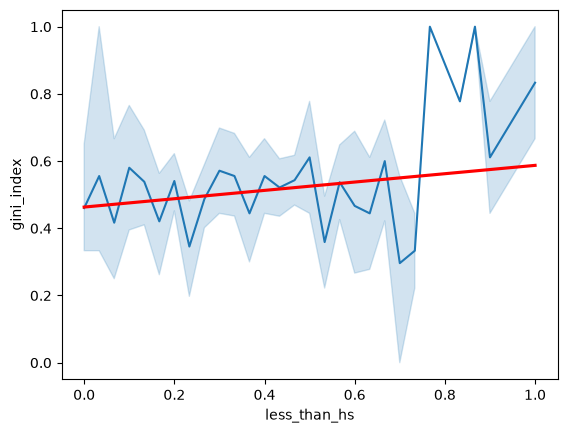

In [9]:
#data_gini_less = data[['less_than_hs', 'gini_index']].copy()
#data_gini_less.sort_values('gini_index', ascending=False)
graph = sns.lineplot(data=norm_gini_hs, x='less_than_hs', y='gini_index')
sns.regplot(
    data=norm_gini_hs,
    x="less_than_hs",
    y="gini_index",
    scatter=False,
    ci=None,
    color="red",
    ax=graph
)
plt.show()

In [10]:
slope, intercept = np.polyfit(
    norm_gini_hs["less_than_hs"],
    norm_gini_hs["gini_index"],
    1
)
print(f"Slope: {slope:.4f}")

Slope: 0.1241


In [11]:
data.select_dtypes('object').columns
#data.groupby('school_district').size()
data_nocategory = data.select_dtypes(exclude='object')
data_nocategory.columns

C:\Users\lilys\AppData\Local\Temp\ipykernel_24388\2262316113.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.select_dtypes('object').columns


Index(['ncessch', 'fips_county_code', 'zip_code', 'sab_available',
       'gini_index', 'economic', 'education', 'health', 'housing', 'crime',
       'composite_score', 'economic_percentile_rank',
       'education_percentile_rank', 'health_percentile_rank',
       'housing_percentile_rank', 'crime_percentile_rank',
       'composite_score_percentile_rank', 'economic_median',
       'education_median', 'health_median', 'housing_median', 'crime_median',
       'composite_score_median', 'unemployment', 'poverty',
       'access_to_broadband_internet', 'single_parent_households',
       'linguistic_isolation', 'access_to_healthcare', 'infant_mortality_rate',
       'snap_recipients', 'low_birth_weight', 'lead_exposure_risk',
       'housing_vacancy_rate', 'housing_affordability', 'park_access',
       'violent_crime_rate', 'incarceration_rate', 'less_than_hs',
       'x2_year_college_or_higher', 'x2_year_college', 'x4_year_college',
       'graduate_or_professional_degree', 'white_alone',

In [12]:
corr_matrix = data_nocategory.corr()
#print(corr_matrix)
# plt.figure(figsize=(14, 10))
# sns.heatmap(corr_matrix, annot=False, fmt=".2f", cmap="coolwarm", center=0)
# plt.tight_layout()
# plt.show()

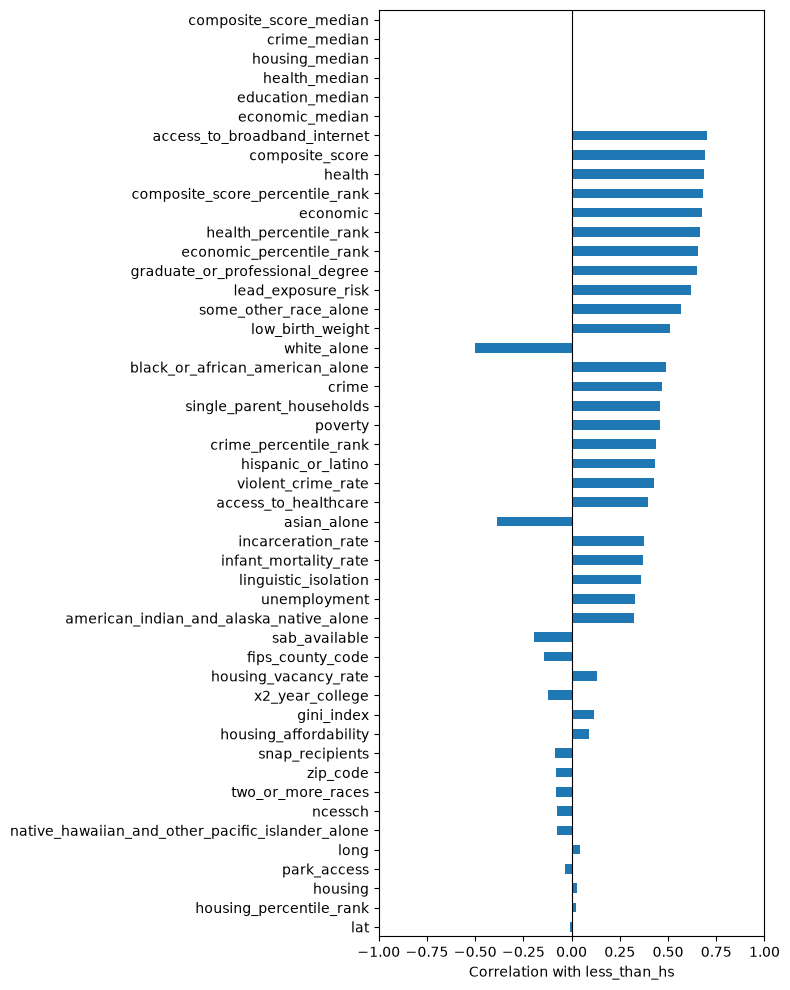

In [13]:
target_corr = corr_matrix["less_than_hs"].drop(["less_than_hs",'education_percentile_rank','education','x2_year_college_or_higher','x4_year_college'])
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=True).index
)

ax = target_corr.plot(kind="barh", figsize=(8, 10))
ax.set_xlabel("Correlation with less_than_hs")
ax.set_xlim(-1, 1)
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

Top 10 Correlations with less_than_hs:
access_to_broadband_internet       0.703768
composite_score                    0.689809
health                             0.687514
composite_score_percentile_rank    0.682114
economic                           0.674191
health_percentile_rank             0.667047
economic_percentile_rank           0.653290
graduate_or_professional_degree    0.649243
lead_exposure_risk                 0.621316
some_other_race_alone              0.567727
Name: less_than_hs, dtype: float64

Top 10 Absolute Correlations with less_than_hs:
access_to_broadband_internet       0.703768
composite_score                    0.689809
health                             0.687514
composite_score_percentile_rank    0.682114
economic                           0.674191
health_percentile_rank             0.667047
economic_percentile_rank           0.653290
graduate_or_professional_degree    0.649243
lead_exposure_risk                 0.621316
some_other_race_alone              0.5677

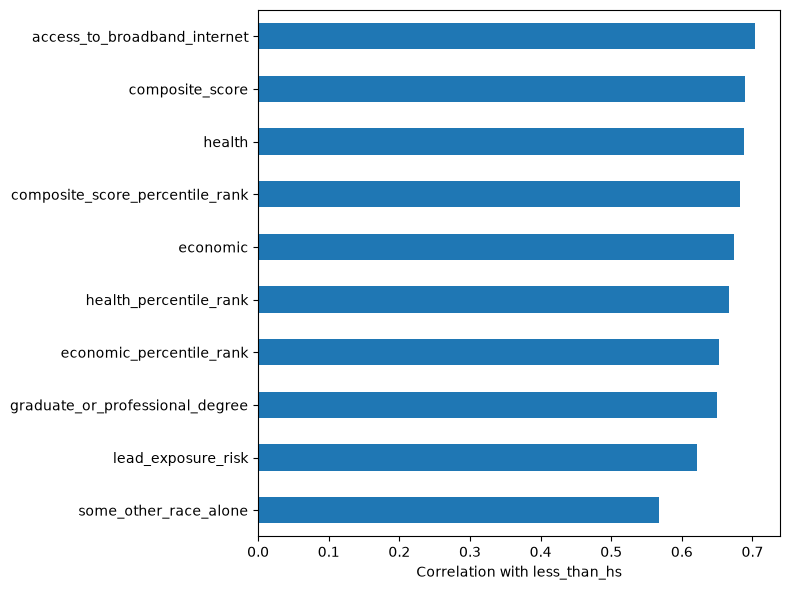

In [14]:
list_of_corrs = target_corr.sort_values(ascending=False).head(10)
list_of_abscorrs = target_corr.abs().sort_values(ascending=False)#.head(10)
print("Top 10 Correlations with less_than_hs:")
print(list_of_corrs)
print("\nTop 10 Absolute Correlations with less_than_hs:")
print(list_of_abscorrs.head(10))
bar_data = target_corr.sort_values(ascending=False).head(10)
ax = bar_data.sort_values().plot(kind="barh", figsize=(8, 6))
ax.set_xlabel("Correlation with less_than_hs")
plt.tight_layout()
plt.show()

In [15]:
target_2 = 'sab_available'
target_corr_2 = corr_matrix[target_2].drop(target_2)
target_corr_2 = target_corr_2.reindex(
    target_corr_2.abs().sort_values(ascending=False).index
)
list_of_corrs2 = target_corr_2.sort_values(ascending=False).head(10)
list_of_abscorrs2 = target_corr_2.abs().sort_values(ascending=False).head(10)
print(f"Top 10 Correlations with {target_2}:")
print(list_of_corrs2)
print(f"\nTop 10 Absolute Correlations with {target_2}:")
print(list_of_abscorrs2)
#barh = list_of_corrs2.plot(kind="barh", figsize=(8, 10))

Top 10 Correlations with sab_available:
housing_percentile_rank    0.316390
park_access                0.309637
housing                    0.291385
zip_code                   0.250559
white_alone                0.158207
ncessch                    0.133446
incarceration_rate         0.129015
unemployment               0.122905
crime                      0.112697
crime_percentile_rank      0.091452
Name: sab_available, dtype: float64

Top 10 Absolute Correlations with sab_available:
housing_percentile_rank      0.316390
park_access                  0.309637
housing                      0.291385
zip_code                     0.250559
x2_year_college              0.242306
linguistic_isolation         0.241230
hispanic_or_latino           0.220224
lead_exposure_risk           0.215120
education_percentile_rank    0.210644
education                    0.209835
Name: sab_available, dtype: float64


In [16]:
feature = "less_than_hs"

county_values = (
    data.groupby("county")[feature]
    .mean()
    .sort_values(ascending=False)
)

county_values#.head(10)

county
Robeson County        31.250000
Edgecombe County      28.000000
Lenoir County         26.000000
Davidson County       26.000000
Randolph County       25.500000
Nash County           22.000000
Alamance County       21.500000
Harnett County        21.000000
Surry County          20.000000
Gaston County         19.250000
Rowan County          19.000000
Pitt County           18.500000
Durham County         18.250000
Guilford County       18.173913
Catawba County        18.000000
Mecklenburg County    17.666667
Forsyth County        17.076923
Craven County         17.000000
Hoke County           15.000000
Cabarrus County       14.900000
Henderson County      14.000000
Buncombe County       12.800000
Cumberland County     12.750000
Brunswick County      12.000000
Wake County           11.838710
Onslow County         11.000000
Orange County         10.750000
Iredell County        10.500000
New Hanover County    10.400000
Union County          10.000000
Johnston County       10.000000
R

In [17]:
target2_values = (
    data.groupby("name")[target_2]
    .mean()
    .sort_values(ascending=True)
)

target2_values#.head(10)

name
Apex Friendship High             0.0
Bethany Community School         0.0
Citi High School                 0.0
Charlotte Secondary              0.0
Carter High School               0.0
                                ... 
Western Guilford High            1.0
Westover High                    1.0
White Oak High                   1.0
William Amos Hough High          1.0
Wilmington Early College High    1.0
Name: sab_available, Length: 206, dtype: float64

**Predictive Functions**

In [18]:
y = data_nocategory['less_than_hs']
X = data_nocategory.drop(columns='less_than_hs')

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
#print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

**Linear Regression**

In [20]:
feature_list = list_of_abscorrs.head(10).index.tolist()
X_new = data_nocategory[feature_list]
#data_nocategory[feature_list].head(5)
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(X_new, y, test_size=0.2, random_state=2)


In [21]:
feature_list

['access_to_broadband_internet',
 'composite_score',
 'health',
 'composite_score_percentile_rank',
 'economic',
 'health_percentile_rank',
 'economic_percentile_rank',
 'graduate_or_professional_degree',
 'lead_exposure_risk',
 'some_other_race_alone']

In [22]:
#fitting the linear regression model
lr_sk = LinearRegression().fit(X_train_lr, y_train_lr)
#making predicgtions on test set using model
y_pred_lr = lr_sk.predict(X_test_lr)

#normalizing the data using MinMaxScaler and creating a pipeline with LinearRegression
# lr_sk = make_pipeline(
#     MinMaxScaler(),
#     LinearRegression()
# )
# lr_sk.fit(X_train_lr, y_train_lr)
# y_pred_lr = lr_sk.predict(X_test_lr)

In [23]:
print('\nModel Performance\n\nRMSE = %.2f'
    % np.sqrt(mean_squared_error(y_test_lr, y_pred_lr)))

train_r2 = r2_score(y_train_lr, lr_sk.predict(X_train_lr))
test_r2 = r2_score(y_test_lr, y_pred_lr)
print('Train R^2 = %.2f' % train_r2)
print('Test R^2 = %.2f' % test_r2)
# print(' R^2 = %.2f'
#     % r2_score(y_test_lr, y_pred_lr))
cv_scores = cross_val_score(lr_sk, X_train_lr, y_train_lr, cv=5, scoring='r2')
print(f"CV R² scores: {cv_scores}")


Model Performance

RMSE = 2.81
Train R^2 = 0.81
Test R^2 = 0.73
CV R² scores: [0.81224147 0.72993242 0.58540034 0.84754288 0.77205523]


In [24]:
residuals = np.abs(y_test_lr - y_pred_lr)  # absolute errors
RMSE = np.sqrt(mean_squared_error(y_test_lr, y_pred_lr))
within_3 = np.mean(residuals <= RMSE) * 100

print(f"Predictions within {RMSE:.2f} points: {within_3:.1f}%")

Predictions within 2.81 points: 73.8%


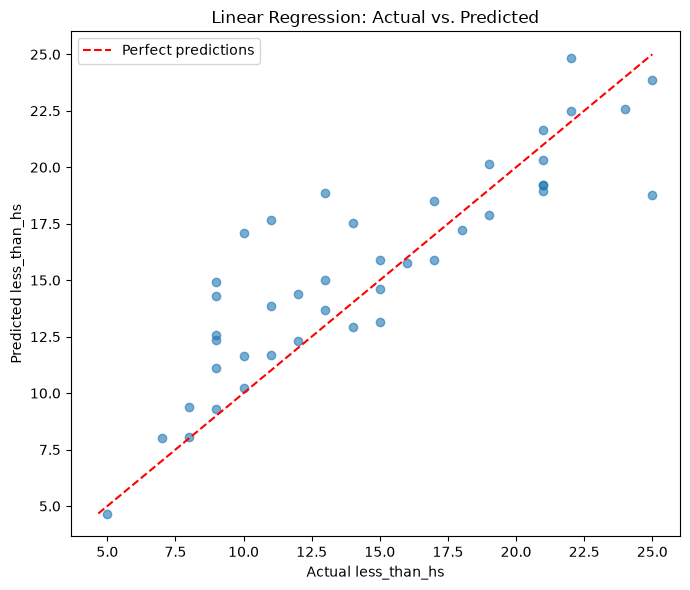

In [25]:

plt.figure(figsize=(7, 6))
plt.scatter(y_test_lr, y_pred_lr, alpha=0.6)

plot_min = min(y_test_lr.min(), y_pred_lr.min())
plot_max = max(y_test_lr.max(), y_pred_lr.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], "r--", label="Perfect predictions")

plt.xlabel("Actual less_than_hs")
plt.ylabel("Predicted less_than_hs")
plt.title("Linear Regression: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
np.min(data['less_than_hs'])
np.max(data['less_than_hs'])
np.std(data['less_than_hs'])

np.float64(6.5668008456124)

**KNN Model**

In [27]:
#Creating the model
knn_model = KNeighborsClassifier(n_neighbors=5)

In [31]:
knn_model.fit(X_train, y_train)
predictions = knn_model.predict(X_train)
accuracy = accuracy_score(predictions , y_train)
accuracy

0.23636363636363636

In [ ]:
accuracy_scores = np.array(cross_val_score(model, X_train, y_train, cv = 3))

- KFold separates training data into n subsets of rows
- then train on each subset and evaluate

In [ ]:
num_folds = 5
folds = KFold(n_splits = num_folds, random_state=None)
acc_scores = []
for train_row_index , test_row_index in folds.split(X_train):
    #new partition of X_train and X_val
    X_train_new = X_train.iloc[train_row_index]
    X_val = X_train.iloc[test_row_index]

    #new partition of y_train and y_val
    y_train_new = y_train.iloc[train_row_index]
    y_val = y_train.iloc[test_row_index]
    knn_model.fit(X_train_new, y_train_new)
    predictions = knn_model.predict(X_val)
    iteration_accuracy = accuracy_score(predictions , y_val)
    acc_scores.append(iteration_accuracy)

for i in range(len(acc_scores)):
    print('Accuracy score for iteration {0}: {1}'.format(i+1, acc_scores[i]))

avg_scores = sum(acc_scores)/num_folds
print('\nAverage accuracy score: {}'.format(avg_scores))